# 02 楠梓外氣氣候分析（Climate，Nanzih）

**核心對象**：一張楠梓氣象站的逐時寬表，每一列是一個整點，欄位有氣溫 `T`、露點 `Td`、相對濕度 `RH`、測站氣壓 `P`、風速 `WS`、風向 `WD`、最大陣風 `gust`、時雨量 `rain`，再加上本 notebook 計算出的濕度比 `W`、焓 `h`、濕球溫度 `Twb`。潔淨室空調的外氣負荷（MAU 冷卻除濕、冷卻水塔、free cooling）全部由這幾個量決定，所以後面每張表都從這張寬表出發。

**輸入**：中央氣象署「高雄」站點（站號 467441）的逐時觀測。這個站 2022 年 1 月 24 日起設在**高雄市楠梓區德民路 28 號**（海拔 11.8 m），距環境部楠梓空品測站約 1.6 km，就在候選廠址旁邊；代價是只有 2022 年起的資料。資料來自氣象署氣候資料服務系統 CODiS 的查詢介面（ https://codis.cwa.gov.tw/StationData ），以程式逐月抓取並快取到 `data/raw/cwa/<站號>/<年-月>.json`，之後離線重跑不需再連線。這個來源不需要 API key。

**輸出**：

- `data/processed/02_design_inputs_Nanzih.csv`：**設計主要資料**，長格式（category、item、metric、value、unit、note），內容有四類：
  - **DESIGN_COOLING**：ASHRAE 形式的夏季設計條件，0.4％、1％、2％ 的乾球溫度（附同時濕球）、濕球溫度（附同時乾球）、焓（附同時乾球），給 MAU 冷卻除濕盤管與冷卻水塔選型用；取哪個百分位由設計組決定。
  - **DESIGN_HEATING**：99.6％、99％ 的乾球溫度，給 MAU 預熱盤管判斷用。
  - **EXTREME**：逐年極端乾球、濕球的平均與最高（最低）值，給設備耐候與安全餘裕參考。
  - **FREECOOL**：濕球或乾球低於各門檻的年小時數，給 free cooling（外氣夠冷時用冷卻水塔直接供冷）可行小時評估用；門檻要用哪一個由設計組依冰水回水溫度與水塔趨近溫度決定。
- `data/processed/02_climate_annual_stats_Nanzih.csv`：各變數逐年的平均、P1、P50、P99、最低、最高與有效率。
- `data/processed/02_climate_profiles_Nanzih.csv`：月剖面與日剖面（kind、var、bin、value）。
- `data/processed/02_climate_bin_hours_Nanzih.csv`：乾球（每 2℃）與濕球（每 1℃）的 bin 小時數，附乾球 bin 的同時濕球平均。
- `data/processed/02_climate_hourly_Nanzih.csv`：逐時寬表（含算出來的 W、h、Twb），供其他分析重用。
- 圖 `report/figures/02_*.png`：累積頻率曲線、焓濕圖散布、月剖面、日剖面、free cooling 月小時數。

**內容說明**：第 1 節是全部設定，換站、換年、改門檻只改那一個 cell；第 2 節抓資料並做成寬表；第 3 節算濕空氣性質；第 4 節算 ASHRAE 形式的設計條件；第 5 節算剖面與 bin 小時數；第 6 節彙整成設計輸入表；第 7 節印出摘要。每節開頭的說明寫「為什麼這樣做」，做法本身看程式碼。

## 1. 設定

所有會變動的東西集中在這一個 cell：測站、年份、路徑、變數對應、設計百分位、free cooling 門檻。

測站清單裡留了舊高雄站（467440，前鎮，1931～2022）與三個自動站（橋頭、大社、仁武，2013 起），要拉長年份或做對照時把站號填進 `EXTRA_STATIONS` 即可；自動站沒有露點與海平面氣壓，露點由本 notebook 自算。

In [22]:
from pathlib import Path
import json, math, ssl, time
import urllib.request, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 路徑：notebook 在 notebooks/ 下執行時，專案根目錄是上一層
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT / "data" / "raw" / "cwa"
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "report" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
PREFIX = "02"                      # 輸出檔名前綴
SITE_EN = "Nanzih"                 # 輸出檔名用的地點代號，一律英文

# ---- 測站（來源：CODiS 測站清單 API，2026-10-24 查詢；座標 WGS84）
STATION_META = pd.DataFrame(
    [["467441", "高雄", "cwb", 22.730432, 120.312516, 11.8, "高雄市楠梓區德民路28號", "2022-01-24", ""],
     ["467440", "高雄（舊站）", "cwb", 22.565992, 120.315733, 2.3, "高雄市前鎮區漁港南二路2號", "1931-01-01", "2022-01-24"],
     ["C0V760", "橋頭", "auto_C0", 22.757806, 120.305750, 30.0, "橋頭區隆豐路1號（橋頭區公所）", "2013-08-30", ""],
     ["C0V770", "大社", "auto_C0", 22.730306, 120.346639, 26.0, "大社區自強街1號（大社區公所）", "2013-09-18", ""],
     ["C0V680", "仁武", "auto_C0", 22.701083, 120.347722, 40.0, "仁武區中正路133號（仁武區公所）", "2013-08-16", ""]],
    columns=["stn_id", "name", "stn_type", "lat", "lon", "alt_m", "address", "start", "end"]).set_index("stn_id")
STATION = "467441"                 # 主站
EXTRA_STATIONS = []                # 對照站或拉長年份用，例如 ["467440"]；留空只跑主站
STATIONS = [STATION] + EXTRA_STATIONS
YEAR_START, YEAR_END = 2022, 2025  # 主站 2022-01-24 才設站，2022 年 1 月只有 8 天
MONTHS = pd.period_range(f"{YEAR_START}-01", f"{YEAR_END}-12", freq="M")
YEARS = list(range(YEAR_START, YEAR_END + 1))

# ---- 變數對應：欄名 → CODiS JSON 的兩層鍵；自動站沒有露點與海平面氣壓
VARS = {"T": ("AirTemperature", "Instantaneous"), "Td": ("DewPointTemperature", "Instantaneous"),
        "RH": ("RelativeHumidity", "Instantaneous"), "P": ("StationPressure", "Instantaneous"),
        "WS": ("WindSpeed", "Mean"), "WD": ("WindDirection", "Mean"),
        "gust": ("PeakGust", "Maximum"), "rain": ("Precipitation", "Accumulation")}
UNITS = {"T": "°C", "Td": "°C", "RH": "%", "P": "hPa", "WS": "m/s", "WD": "deg", "gust": "m/s", "rain": "mm",
         "W": "g/kg", "h": "kJ/kg", "Twb": "°C", "Td_calc": "°C"}
LABELS = {"T": "乾球溫度", "Td": "露點溫度", "RH": "相對濕度", "P": "測站氣壓", "WS": "風速", "WD": "風向",
          "gust": "最大陣風", "rain": "時雨量", "W": "濕度比", "h": "焓", "Twb": "濕球溫度", "Td_calc": "露點（計算）"}

# ---- 統計參數
COOLING_PCT = [0.4, 1.0, 2.0]      # ASHRAE 夏季設計條件：一年中被超過的小時比例（0.4% ≈ 35 h、1% ≈ 88 h、2% ≈ 175 h）
HEATING_PCT = [99.6, 99.0]         # ASHRAE 冬季設計條件：一年中被超過的小時比例（99.6% → 只有 35 h 更冷）
WB_THRESHOLDS = [8, 10, 12, 14, 16, 18, 20]   # free cooling 濕球門檻（°C），哪一個適用由設計組依冰水回水溫度與水塔趨近溫度決定
DB_THRESHOLDS = [12, 15, 18, 20, 22]          # 乾球門檻（°C），給空氣側 free cooling／預冷參考
DB_BIN, WB_BIN = 2, 1              # bin 小時數的 bin 寬（°C）
COVERAGE_MIN = 0.75                # 某變數某年有效率低於此值時標示「有效率不足」
COINCIDENT_HALF_WIDTH = 0.5        # 算「同時濕球／同時乾球」時取設計值 ±0.5°C 內的小時平均（焓用 ±1 kJ/kg）

# ---- 哨兵值：CODiS 的 JSON 把缺測寫成數值而不是旗標（網頁上顯示為 x 儀器故障、T 微量）
#      實測 467441 四年出現的有：T/Td/WS/gust −99.5、RH −9995、P −9999.5、WD/rain −999.5、rain −9.8（雨跡，<0.5 mm）
SENTINEL_MIN = {"T": -50, "Td": -50}   # 溫度類：低於 −50°C 視為哨兵；其他變數不可能為負，小於 −9 即視為哨兵
TRACE_RAIN = -9.8                      # 雨跡：以 0 mm 計，旗標記 T

# ---- 繪圖設定
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

print("PROJECT =", PROJECT)
print("STATIONS =", STATIONS, "|", MONTHS[0], "→", MONTHS[-1])

PROJECT = c:\Users\user\Desktop\交通大學研究所\碩二(下)課程\TSMC_Project
STATIONS = ['467441'] | 2022-01 → 2025-12


## 2. 下載與載入

**為什麼用 CODiS 的查詢介面而不是氣象署開放平台**：開放平台（opendata.cwa.gov.tw）給的是即時觀測與預報，逐時歷史資料不在那裡；CODiS 才有 1931 年起的逐時觀測。CODiS 的網頁背後是一個 `POST /api/station` 的請求，參數是站號、站型與起訖時間，一次最多一個月（跨年會回 400），所以程式逐月抓，四年 48 次、每次約 1 秒。抓到的 JSON 原樣存進 `data/raw/cwa/<站號>/<年-月>.json`，再跑時直接讀快取，不重抓；要重抓就刪那個檔。

**欄位**：從 JSON 取出 8 個觀測變數，欄名與意義如下；「CODiS 鍵」是 JSON 裡的兩層鍵，第二層表示這一小時的值怎麼取（Instantaneous 整點觀測值、Mean 平均、Maximum 該小時最大、Accumulation 該小時累積）。下方輸出的旗標統計與有效率表都用這些欄名。

| 欄名 | 名稱 | 單位 | CODiS 鍵 | 意義 |
|---|---|---|---|---|
| `T` | 乾球溫度（氣溫） | °C | AirTemperature / Instantaneous | 一般說的氣溫，溫度計直接量空氣的溫度 |
| `Td` | 露點溫度 | °C | DewPointTemperature / Instantaneous | 空氣在含水量不變下降溫到開始結露的溫度，露點越高代表空氣含水越多；只有有人站有量 |
| `RH` | 相對濕度 | % | RelativeHumidity / Instantaneous | 空氣中水蒸氣分壓占同溫度飽和水蒸氣壓的比例，100％ 為飽和 |
| `P` | 測站氣壓 | hPa | StationPressure / Instantaneous | 測站所在高度的實際氣壓，不是換算到海平面的氣壓 |
| `WS` | 風速 | m/s | WindSpeed / Mean | 平均風速 |
| `WD` | 風向 | 度 | WindDirection / Mean | 風**吹來**的方向，0°（360°）為北、90° 為東、180° 為南、270° 為西 |
| `gust` | 最大陣風 | m/s | PeakGust / Maximum | 該小時內出現的最大瞬間風速 |
| `rain` | 時雨量 | mm | Precipitation / Accumulation | 該小時的累積降雨量 |

`T`、`RH`、`P` 是第 3 節計算濕度比 `W`、焓 `h`、濕球溫度 `Twb` 的輸入，同一小時缺任一個，這三個計算值就是空值；`Td` 用來和第 3 節自算的露點 `Td_calc` 對照。風與雨不進入外氣負荷的計算，只列在年統計（`WS`、`gust`、`rain`）與月、日剖面（`WS`）供參考。

**時間的慣例**：氣象署逐時值是「整點前一小時」的觀測，標記為該整點（01:00 代表 00:00～01:00），而 24:00 在 JSON 裡寫成 `23:59:00`。本表把時間戳統一改成**該小時的起始時刻**（01:00 → 00:00，23:59 → 23:00），好處是同一天的 24 筆都落在同一個日期，依日、月、小時分組時不用再特別處理跨日。

**無效值**：氣象署的說明文件（CODiS Readme）定義網頁上的符號是 `x` 儀器故障、`T` 微量降水（< 0.5 mm）、`/` 不明、`--` 無觀測，但 JSON 裡這些不是放在旗標欄（以 `f` 結尾的 `Instantaneousf` 等欄位四年都是 `null`），而是直接寫成**哨兵數值**(不可能出現的數字)：氣溫、露點、風速、陣風用 −99.5，相對濕度用 −9995，測站氣壓用 −9999.5，風向與雨量用 −999.5，雨跡用 −9.8。本表的規則：溫度類低於 −50℃、其他變數小於 −9 的值一律視為缺測，數值轉成 NaN 並在 `<變數>_f` 欄記 `x`；雨量 −9.8 是「有降水但不足 0.5 mm」，以 0 mm 計並記 `T`。保留旗標欄是為了算有效率，也讓讀者能回查哪些小時被剔除。

**TLS 憑證**：Python 3.13 預設開啟嚴格憑證檢查（`VERIFY_X509_STRICT`），氣象署的憑證缺少 Subject Key Identifier 欄位會被拒絕；下方自訂的 SSL context 只關掉這個嚴格旗標，憑證鏈仍然驗證。

In [23]:
API_URL = "https://codis.cwa.gov.tw/api/station"
HEADERS = {"User-Agent": "Mozilla/5.0", "X-Requested-With": "XMLHttpRequest",
           "Referer": "https://codis.cwa.gov.tw/StationData",
           "Content-Type": "application/x-www-form-urlencoded; charset=UTF-8"}
SSL_CTX = ssl.create_default_context()
SSL_CTX.verify_flags &= ~ssl.VERIFY_X509_STRICT


def fetch_month(stn_id: str, stn_type: str, period: pd.Period) -> dict:
    '''抓一站一個月的逐時 JSON；有快取就讀快取。'''
    cache = RAW_DIR / stn_id / f"{period}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    start = period.start_time.strftime("%Y-%m-%dT00:00:00")
    end = period.end_time.strftime("%Y-%m-%dT23:59:59")
    body = urllib.parse.urlencode({"date": start + "+08:00", "type": "report_date", "stn_ID": stn_id,
                                   "stn_type": stn_type, "more": "", "start": start, "end": end, "item": ""}).encode()
    req = urllib.request.Request(API_URL, data=body, method="POST", headers=HEADERS)
    for attempt in range(3):
        try:
            with urllib.request.urlopen(req, context=SSL_CTX, timeout=60) as r:
                payload = json.loads(r.read().decode("utf-8"))
            break
        except Exception as e:            # 網路暫時失敗就重試，三次都失敗才拋出
            if attempt == 2:
                raise
            time.sleep(3)
    if payload.get("code") != 200:
        raise RuntimeError(f"{stn_id} {period}: {payload.get('message')}")
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(payload, ensure_ascii=False), encoding="utf-8")
    time.sleep(0.3)                       # 禮貌性間隔
    return payload


def parse_month(payload: dict, stn_id: str) -> pd.DataFrame:
    '''JSON → 寬表（一列一小時）。時間改成小時起始時刻；旗標留在 <var>_f 欄。'''
    recs = ((payload.get("data") or [{}])[0].get("dts")) or []
    rows = []
    for d in recs:
        row = {"stn_id": stn_id, "datetime": d["DataTime"]}
        for col, (k1, k2) in VARS.items():
            node = d.get(k1) or {}
            row[col] = node.get(k2)
            row[col + "_f"] = node.get(k2 + "f")
        rows.append(row)
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    ts = pd.to_datetime(df["datetime"])
    ts = ts.where(ts.dt.minute != 59, ts + pd.Timedelta(minutes=1))   # 23:59 代表 24:00
    df["datetime"] = ts - pd.Timedelta(hours=1)                       # 改成小時起始時刻
    for col in VARS:
        v = pd.to_numeric(df[col], errors="coerce")
        flag = df[col + "_f"].astype("string")
        if col == "rain":
            trace = v == TRACE_RAIN
            flag = flag.mask(trace, "T")
            v = v.mask(trace, 0.0)
        sentinel = v < SENTINEL_MIN.get(col, -9)
        flag = flag.mask(sentinel, "x")
        df[col] = v.mask(sentinel)
        df[col + "_f"] = flag
    return df


def load_station(stn_id: str) -> pd.DataFrame:
    stn_type = STATION_META.loc[stn_id, "stn_type"]
    frames = [parse_month(fetch_month(stn_id, stn_type, p), stn_id) for p in MONTHS]
    df = pd.concat([f for f in frames if not f.empty], ignore_index=True)
    return df.drop_duplicates("datetime").sort_values("datetime").reset_index(drop=True)


def coverage(df: pd.DataFrame, cols) -> pd.DataFrame:
    '''變數 × 年的有效小時比例，分母是該年的總小時數（不是抓到的筆數），設站前的月份會直接反映成低有效率。'''
    year = df["datetime"].dt.year
    hours_in_year = pd.Series({y: pd.Timestamp(y + 1, 1, 1) - pd.Timestamp(y, 1, 1) for y in YEARS}).dt.total_seconds() / 3600
    valid = df[cols].notna().groupby(year).sum()
    return (valid.T / hours_in_year.reindex(valid.index)).T.round(3)


def flag_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in VARS:
        s = df[col + "_f"].dropna()
        for code_, n in s.value_counts().items():
            rows.append({"var": col, "flag": code_, "count": int(n)})
    return pd.DataFrame(rows, columns=["var", "flag", "count"])


t0 = time.time()
hourly = pd.concat([load_station(s) for s in STATIONS], ignore_index=True)
main = hourly[hourly["stn_id"] == STATION].drop(columns="stn_id").set_index("datetime").sort_index()
print(f"主站 {STATION} 逐時列數 {len(main):,} | 期間 {main.index.min()} → {main.index.max()} | 載入 {time.time() - t0:.0f} s")
cov = coverage(main.reset_index(), list(VARS))
display(flag_summary(hourly))
display(cov)

主站 467441 逐時列數 34,512 | 期間 2022-01-24 00:00:00 → 2025-12-31 23:00:00 | 載入 3 s


,var,flag,count
0,T,x,6
1,Td,x,6
2,RH,x,6
3,P,x,147
4,WS,x,44
5,WD,x,44
6,gust,x,33
7,rain,T,1361
8,rain,x,6


,T,Td,RH,P,WS,WD,gust,rain
datetime,,,,,,,,
2022,0.937,0.937,0.937,0.934,0.932,0.932,0.933,0.937
2023,1.000,1.000,1.000,0.988,1.000,1.000,1.000,1.000
2024,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2025,1.000,1.000,1.000,0.999,1.000,1.000,1.000,1.000


## 3. 濕空氣性質計算

測站給的是乾球溫度、相對濕度、測站氣壓（有人站另給露點），但 MAU 盤管容量與冷卻水塔看的是**焓**與**濕球溫度**：盤管要把外氣從外氣焓降到送風焓，容量正比於焓差；冷卻水塔的出水溫度是濕球加趨近溫度，所以水塔容量由設計濕球決定。這兩個量測站不直接量，要從乾球、相對濕度、氣壓算出來。

計算依 ASHRAE Handbook Fundamentals（2017）第 1 章的公式，全部向量化處理整張表：

- **飽和水蒸氣壓** $p_{ws}(T)$：Hyland–Wexler 式（式 5、6），0℃ 以上用水面、以下用冰面。
- **水蒸氣分壓** $p_w = \phi \, p_{ws}(T)$，$\phi$ 為相對濕度。
- **濕度比** $W = 0.621945 \, p_w / (p - p_w)$（kg 水／kg 乾空氣），$p$ 用**測站氣壓**而不是海平面氣壓，因為空氣的實際狀態在測站高度。
- **焓** $h = 1.006\,t + W\,(2501 + 1.86\,t)$（kJ/kg 乾空氣）。
- **濕球溫度** $t^*$：解 $W = \dfrac{(2501 - 2.326\,t^*)\,W_s^* - 1.006\,(t - t^*)}{2501 + 1.86\,t - 4.186\,t^*}$，$W_s^*$ 是 $t^*$ 下的飽和濕度比。右式對 $t^*$ 單調遞增，且 $t^*$ 一定落在露點與乾球之間，所以用二分法 40 次迭代就收斂到 10⁻⁶℃ 以下。
- **露點** $t_d$：由 $p_w$ 用式 39、40 的多項式反算；有人站自己有量露點，這裡另算一欄 `Td_calc` 是為了自動站（沒有露點）也能走同一套流程。

濕度比在表中以 g/kg 顯示（乘 1000），計算時仍用 kg/kg。

In [24]:
def p_ws(t_c):
    '''飽和水蒸氣壓（Pa），ASHRAE 2017 Fundamentals Ch.1 式(5)(6)。'''
    T = np.asarray(t_c, dtype=float) + 273.15
    with np.errstate(invalid="ignore", divide="ignore"):
        water = (-5.8002206e3 / T + 1.3914993 - 4.8640239e-2 * T + 4.1764768e-5 * T ** 2
                 - 1.4452093e-8 * T ** 3 + 6.5459673 * np.log(T))
        ice = (-5.6745359e3 / T + 6.3925247 - 9.677843e-3 * T + 6.2215701e-7 * T ** 2
               + 2.0747825e-9 * T ** 3 - 9.484024e-13 * T ** 4 + 4.1635019 * np.log(T))
        return np.exp(np.where(T >= 273.15, water, ice))


def humidity_ratio(p_w, p):
    return 0.621945 * p_w / (p - p_w)


def enthalpy(t, W):
    return 1.006 * t + W * (2501 + 1.86 * t)


def dew_point(p_w):
    '''露點（°C），ASHRAE 式(39)(40)，p_w 單位 Pa。'''
    with np.errstate(invalid="ignore", divide="ignore"):
        pw_kpa = np.asarray(p_w, dtype=float) / 1000
        a = np.log(pw_kpa)
        warm = 6.54 + 14.526 * a + 0.7389 * a ** 2 + 0.09486 * a ** 3 + 0.4569 * pw_kpa ** 0.1984
        cold = 6.09 + 12.608 * a + 0.4959 * a ** 2
        return np.where(warm >= 0, warm, cold)


def wet_bulb(t, W, p, t_low, n_iter=40):
    '''濕球溫度（°C）：在 [露點, 乾球] 之間二分法解 ASHRAE 式(33)。'''
    t = np.asarray(t, dtype=float); W = np.asarray(W, dtype=float); p = np.asarray(p, dtype=float)
    lo = np.minimum(np.asarray(t_low, dtype=float), t)
    hi = t.copy()
    for _ in range(n_iter):
        mid = (lo + hi) / 2
        Ws = humidity_ratio(p_ws(mid), p)
        W_est = ((2501 - 2.326 * mid) * Ws - 1.006 * (t - mid)) / (2501 + 1.86 * t - 4.186 * mid)
        too_high = W_est > W
        hi = np.where(too_high, mid, hi)
        lo = np.where(too_high, lo, mid)
    twb = (lo + hi) / 2
    return np.where(np.isnan(t) | np.isnan(W) | np.isnan(p), np.nan, twb)   # 任一輸入缺測就不給值，否則二分法會收斂到乾球


def add_psychrometrics(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    p_pa = out["P"] * 100.0
    pw = out["RH"] / 100.0 * p_ws(out["T"])
    W = humidity_ratio(pw, p_pa)
    out["W"] = W * 1000.0                                   # g/kg 顯示用
    out["h"] = enthalpy(out["T"], W)
    out["Td_calc"] = dew_point(pw)
    out["Twb"] = wet_bulb(out["T"], W, p_pa, out["Td_calc"] - 0.5)
    return out


main = add_psychrometrics(main)
main.round(3).to_csv(PROC_DIR / f"{PREFIX}_climate_hourly_{SITE_EN}.csv")
print("算完濕空氣性質的逐時表（前 5 列）：")
display(main[["T", "RH", "P", "Td", "Td_calc", "W", "h", "Twb"]].head())

算完濕空氣性質的逐時表（前 5 列）：


,T,RH,P,Td,Td_calc,W,h,Twb
datetime,,,,,,,,
2022-01-24 00:00:00,19.9,93.0,1011.4,18.7,18.752634,13.583048,54.493367,19.111676
2022-01-24 01:00:00,19.6,95.0,1011.0,18.8,18.795012,13.625501,54.291710,19.043426
2022-01-24 02:00:00,19.3,96.0,1011.2,18.6,18.664468,13.509203,53.687270,18.859060
2022-01-24 03:00:00,18.8,98.0,1010.6,18.5,18.496024,13.372061,52.823919,18.583174
2022-01-24 04:00:00,18.9,97.0,1010.5,18.4,18.432298,13.318792,52.791906,18.573256


## 4. 設計條件（ASHRAE 形式）與年統計

**為什麼用「被超過的小時比例」而不是最大值**：設計盤管與水塔若按歷史最大值選，設備一年中絕大多數時間都在大材小用；ASHRAE 的做法是取一年中只有 0.4％（約 35 小時）、1％（88 小時）、2％（175 小時）會被超過的值，讓設計組依製程容許的超標時數選。本表把四年的小時值合併後取百分位（0.4％ 對應第 99.6 百分位），和 ASHRAE 氣候設計條件表的算法一致。

**同時值（mean coincident）**：盤管負荷同時取決於乾球與濕球，但「乾球 0.4％」與「濕球 0.4％」通常不在同一個小時發生，直接配對會高估。ASHRAE 的做法是取設計乾球(及乾球平均值) ±0.5℃ 內那些小時對應的濕球平均當「同時濕球」（MCWB），反過來得到「同時乾球」（MCDB）；焓的設計值也配同時乾球。

**冬季設計條件**：99.6％ 與 99％ 代表一年只有 35 與 88 小時更冷，給 MAU 預熱盤管判斷用。

**極端值**：逐年的最高乾球、最高濕球、最低乾球，列出各年平均與各年最極端者；用途是設備耐候與安全餘裕，不是選型基準。

**年統計表**：各變數逐年的平均、P1、P50、P99、最低、最高與有效率，讓讀者看年際差異有多大。

**焓濕圖散布**：每個點是一小時的外氣狀態，橫軸乾球、縱軸濕度比。灰色實線是等相對濕度線，100％ 那條是飽和線，點只會落在它下方。棕色虛線是等焓線：焓只由乾球與濕度比決定（$h = 1.006\,t + W\,(2501 + 1.86\,t)$），往右 1℃ 焓約增加 1 kJ/kg，往上 1 g/kg 約增加 2.5 kJ/kg，所以等焓線往右下斜，越往右上焓越高，而且含水量的影響比溫度大。星號是 0.4％ 乾球與濕球設計點，圖例附上各自的焓。

4.1 設計條件（四年合併小時值）


,season,pct,condition,value,coincident,coincident_value,unit,n_coincident,hours_per_year,n_hours_pooled,n_years
0,cooling,0.4,DB,33.80,MCWB,27.10,°C,269,35.0,34365,4
1,cooling,0.4,WB,28.41,MCDB,31.88,°C,518,35.0,34365,4
2,cooling,0.4,h,92.16,MCDB,31.73,kJ/kg,192,35.0,34365,4
3,cooling,1.0,DB,33.20,MCWB,27.05,°C,653,88.0,34365,4
4,cooling,1.0,WB,28.10,MCDB,31.42,°C,1065,88.0,34365,4
5,cooling,1.0,h,90.59,MCDB,31.53,kJ/kg,375,88.0,34365,4
6,cooling,2.0,DB,32.80,MCWB,27.03,°C,984,175.0,34365,4
7,cooling,2.0,WB,27.83,MCDB,31.05,°C,1728,175.0,34365,4
8,cooling,2.0,h,89.24,MCDB,31.10,kJ/kg,703,175.0,34365,4
9,heating,99.6,DB,11.00,MCWB,9.57,°C,117,35.0,34365,4


4.2 逐年極端值


,DB_max,DB_min,WB_max,h_max
datetime,,,,
2022,34.7,8.0,28.7,93.3
2023,35.2,9.1,29.4,97.1
2024,36.3,9.6,30.0,101.1
2025,34.8,8.1,28.9,94.5


,mean_of_annual,most_extreme
DB_max,35.2,36.3
DB_min,8.7,8.0
WB_max,29.2,30.0
h_max,96.5,101.1


4.3 年統計


mean     min       p1      p50      p99      max  n_valid  \
var  year                                                                 
T    2022    24.99    8.00    11.80    25.80    33.10    34.70     8204   
     2023    24.83    9.10    12.30    25.80    33.00    35.20     8760   
     2024    25.07    9.60    12.98    25.90    33.82    36.30     8784   
     2025    24.54    8.10    12.60    25.60    33.00    34.80     8758   
RH   2022    80.70   27.00    47.00    83.00    99.00   100.00     8204   
     2023    79.29   29.00    46.00    81.00   100.00   100.00     8760   
     2024    82.18   32.00    47.00    84.00   100.00   100.00     8784   
     2025    80.13   17.00    48.00    82.00    98.00   100.00     8758   
Td   2022    21.20    2.40     7.40    22.70    26.70    27.90     8204   
     2023    20.74    1.40     7.76    21.90    27.10    28.90     8760   
     2024    21.55    4.40     8.80    23.40    27.70    29.80     8784   
     2025    20.67    1.80     8.00    22.40    27.20    28.00     8758   
P    2022  1010.21  993.70  1000.90  1010.10  1020.60  1023.10     8178   
     2023  1011.07  982.10   996.00  1011.10  1023.85  1026.70     8652   
     2024  1010.99  977.20   996.03  1010.60  1023.80  1026.30     8784   
     2025  1011.14  985.30   995.70  1011.00  1023.15  1026.60     8751   
W    2022    16.44    4.48     6.37    17.45    22.45    24.06     8178   
     2023    16.15    4.13     6.46    16.65    23.13    25.62     8652   
     2024    16.96    5.15     6.99    18.29    23.86    27.38     8784   
     2025    16.07    4.27     6.62    17.09    23.28    24.56     8751   
h    2022    67.07   21.89    29.55    71.14    88.55    93.32     8178   
     2023    66.24   20.50    29.94    69.22    89.63    97.07     8652   
     2024    68.46   25.04    32.05    73.11    92.30   101.13     8784   
     2025    65.65   21.31    30.02    70.22    90.05    94.47     8751   
Twb  2022    22.33    6.68    10.20    23.71    27.69    28.67     8178   
     2023    22.06    6.03    10.34    23.26    27.90    29.40     8652   
     2024    22.61    8.16    11.26    24.20    28.47    30.04     8784   
     2025    21.85    6.42    10.40    23.48    27.99    28.86     8751   
WS   2022     1.23    0.00     0.10     0.90     4.10     6.10     8166   
     2023     1.23    0.00     0.00     0.80     4.30     8.70     8760   
     2024     1.14    0.00     0.00     0.80     4.10     9.20     8784   
     2025     1.06    0.00     0.00     0.70     3.80     6.50     8758   
gust 2022     3.82    0.00     0.80     3.50    10.00    15.70     8177   
     2023     3.81    0.10     0.70     3.40    10.30    24.60     8760   
     2024     3.72    0.10     0.70     3.30    11.60    22.30     8784   
     2025     3.57    0.10     0.70     3.20     9.30    22.80     8758   
rain 2022     0.12    0.00     0.00     0.00     3.00    60.00     8204   
     2023     0.19    0.00     0.00     0.00     6.00    43.00     8760   
     2024     0.33    0.00     0.00     0.00     8.50    96.50     8784   
     2025     0.21    0.00     0.00     0.00     6.00    67.50     8758   

           coverage  low_coverage   unit  
var  year                                 
T    2022      0.94         False     °C  
     2023      1.00         False     °C  
     2024      1.00         False     °C  
     2025      1.00         False     °C  
RH   2022      0.94         False      %  
     2023      1.00         False      %  
     2024      1.00         False      %  
     2025      1.00         False      %  
Td   2022      0.94         False     °C  
     2023      1.00         False     °C  
     2024      1.00         False     °C  
     2025      1.00         False     °C  
P    2022      0.93         False    hPa  
     2023      0.99         False    hPa  
     2024      1.00         False    hPa  
     2025      1.00         False    hPa  
W    2022      0.93         False   g/kg  
     2023      0.99         False   g/kg  
   

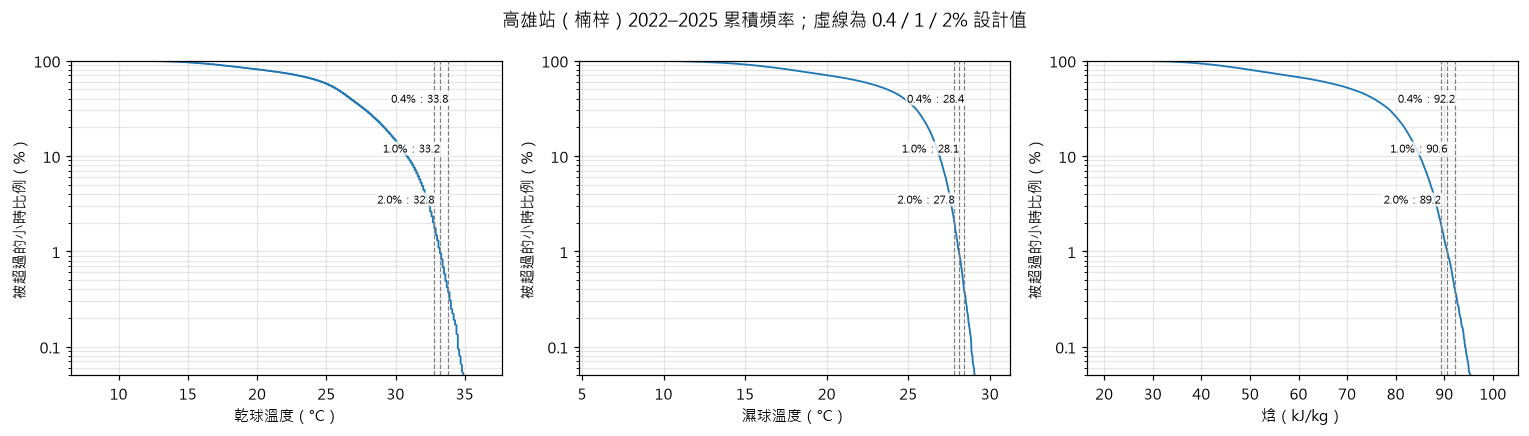

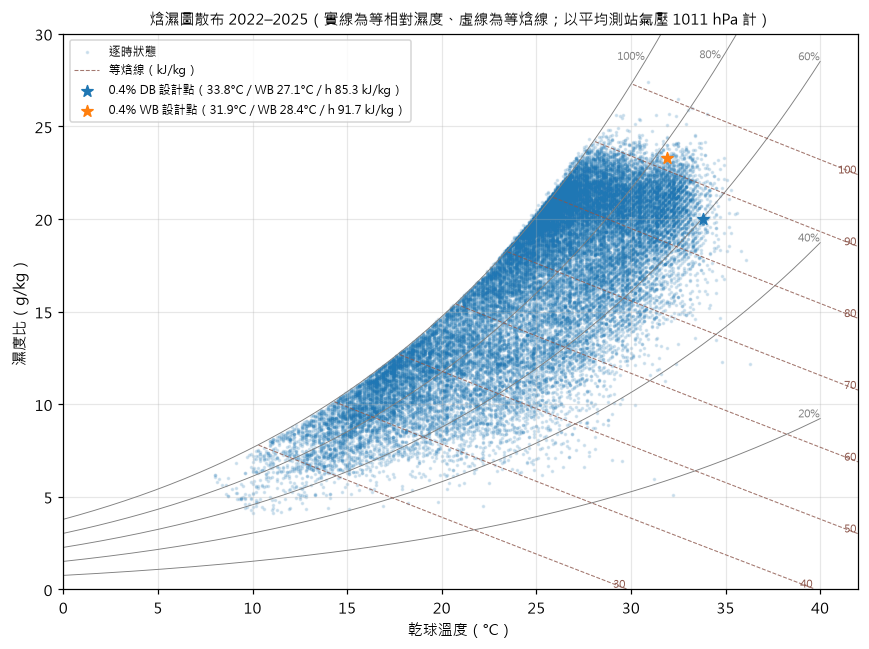

In [25]:
def design_conditions(df: pd.DataFrame) -> pd.DataFrame:
    d = df.dropna(subset=["T", "Twb", "h"])
    n_years = len(d.index.year.unique())
    rows = []

    def coincident(col_sel, val, col_out, half):
        sel = d[(d[col_sel] - val).abs() <= half]
        return sel[col_out].mean(), len(sel)

    for pct in COOLING_PCT:
        q = 1 - pct / 100
        db = d["T"].quantile(q); mcwb, n1 = coincident("T", db, "Twb", COINCIDENT_HALF_WIDTH)
        wb = d["Twb"].quantile(q); mcdb, n2 = coincident("Twb", wb, "T", COINCIDENT_HALF_WIDTH)
        hh = d["h"].quantile(q); mcdb_h, n3 = coincident("h", hh, "T", 1.0)
        rows += [
            {"season": "cooling", "pct": pct, "condition": "DB", "value": db, "coincident": "MCWB", "coincident_value": mcwb, "unit": "°C", "n_coincident": n1},
            {"season": "cooling", "pct": pct, "condition": "WB", "value": wb, "coincident": "MCDB", "coincident_value": mcdb, "unit": "°C", "n_coincident": n2},
            {"season": "cooling", "pct": pct, "condition": "h", "value": hh, "coincident": "MCDB", "coincident_value": mcdb_h, "unit": "kJ/kg", "n_coincident": n3},
        ]
    for pct in HEATING_PCT:
        db = d["T"].quantile(1 - pct / 100); mcwb, n1 = coincident("T", db, "Twb", COINCIDENT_HALF_WIDTH)
        rows.append({"season": "heating", "pct": pct, "condition": "DB", "value": db, "coincident": "MCWB", "coincident_value": mcwb, "unit": "°C", "n_coincident": n1})
    out = pd.DataFrame(rows)
    out["hours_per_year"] = np.where(out["season"] == "cooling", out["pct"] / 100 * 8760, (100 - out["pct"]) / 100 * 8760).round(0)
    out["n_hours_pooled"] = len(d)
    out["n_years"] = n_years
    return out.round(2)


def extremes(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby(df.index.year)
    tbl = pd.DataFrame({"DB_max": g["T"].max(), "DB_min": g["T"].min(), "WB_max": g["Twb"].max(), "h_max": g["h"].max()})
    summary = pd.DataFrame({"mean_of_annual": tbl.mean(), "most_extreme": [tbl["DB_max"].max(), tbl["DB_min"].min(), tbl["WB_max"].max(), tbl["h_max"].max()]},
                           index=tbl.columns)
    return tbl.round(1), summary.round(1)


def annual_stats(df: pd.DataFrame, cols, cov: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in cols:
        g = df[col].groupby(df.index.year)
        t = pd.DataFrame({"mean": g.mean(), "min": g.min(), "p1": g.quantile(0.01), "p50": g.median(),
                          "p99": g.quantile(0.99), "max": g.max(), "n_valid": g.count()})
        t["coverage"] = cov[col] if col in cov else np.nan
        t["low_coverage"] = t["coverage"] < COVERAGE_MIN
        t["unit"] = UNITS[col]
        t.index.name = "year"
        rows.append(t.reset_index().assign(var=col))
    return pd.concat(rows, ignore_index=True).set_index(["var", "year"]).round(2)


design = design_conditions(main)
ext_by_year, ext_summary = extremes(main)
cov_all = cov.join(coverage(main.reset_index(), ["W", "h", "Twb"]))
stats = annual_stats(main, ["T", "RH", "Td", "P", "W", "h", "Twb", "WS", "gust", "rain"], cov_all)
stats.to_csv(PROC_DIR / f"{PREFIX}_climate_annual_stats_{SITE_EN}.csv")
print("4.1 設計條件（四年合併小時值）"); display(design)
print("4.2 逐年極端值"); display(ext_by_year); display(ext_summary)
print("4.3 年統計"); display(stats)

# ---- 圖：累積頻率曲線（乾球、濕球、焓）
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["T", "Twb", "h"]):
    s = np.sort(main[col].dropna().values)[::-1]
    pct_exceeded = np.arange(1, len(s) + 1) / len(s) * 100
    ax.plot(s, pct_exceeded, lw=1.2)
    for pct, y_txt in zip(COOLING_PCT, [40, 12, 3.5]):   # 三條線很近，文字錯開高度
        v = main[col].quantile(1 - pct / 100)
        ax.axvline(v, color="gray", ls="--", lw=0.8)
        ax.text(v, y_txt, f"{pct}%：{v:.1f}", fontsize=7, ha="right", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_yscale("log"); ax.set_ylim(0.05, 100); ax.grid(alpha=0.3, which="both")
    ax.set_yticks([0.1, 1, 10, 100]); ax.set_yticklabels(["0.1", "1", "10", "100"])
    ax.set_xlabel(f"{LABELS[col]}（{UNITS[col]}）"); ax.set_ylabel("被超過的小時比例（%）")
fig.suptitle(f"{STATION_META.loc[STATION, 'name']}站（楠梓）{YEAR_START}–{YEAR_END} 累積頻率；虛線為 0.4／1／2% 設計值")
fig.tight_layout(); fig.savefig(FIG_DIR / f"{PREFIX}_cumulative_frequency_{SITE_EN}.png"); plt.show()

# ---- 圖：焓濕圖散布（乾球 vs 濕度比），疊等相對濕度線、等焓線與設計點
p_mean = main["P"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(main["T"], main["W"], s=2, alpha=0.15, color="tab:blue", label="逐時狀態")
t_line = np.linspace(0, 40, 200)
W_MAX = 30
for rh in [20, 40, 60, 80, 100]:
    W_line = humidity_ratio(rh / 100 * p_ws(t_line), p_mean) * 1000
    ax.plot(t_line, W_line, color="gray", lw=0.6)
    k = np.searchsorted(W_line, W_MAX * 0.95)            # 標籤放在曲線離開圖框前的位置
    k = min(k, len(t_line) - 1)
    ax.text(t_line[k], W_line[k], f"{rh}%", fontsize=7, va="bottom", ha="right", color="gray")
t_h = np.linspace(0, 42, 400)
W_sat = humidity_ratio(p_ws(t_h), p_mean) * 1000
for i, h_iso in enumerate(range(30, 101, 10)):           # 等焓線：h 固定時 W = (h − 1.006t) / (2501 + 1.86t)
    W_h = (h_iso - 1.006 * t_h) / (2501 + 1.86 * t_h) * 1000
    ok = (W_h >= 0) & (W_h <= W_sat)                     # 只畫飽和線以下
    ax.plot(t_h[ok], W_h[ok], color="tab:brown", ls="--", lw=0.7, alpha=0.8, label="等焓線（kJ/kg）" if i == 0 else None)
    k = np.flatnonzero(ok)[-1]                           # 標籤放在線的右下端（碰到 W = 0 或圖框右緣）
    ax.text(t_h[k] - 0.1, W_h[k], f"{h_iso}", fontsize=7, va="bottom", ha="right", color="tab:brown")
for _, r in design[design["pct"] == COOLING_PCT[0]].iterrows():
    if r["condition"] == "DB":
        t_pt, wb_pt = r["value"], r["coincident_value"]
    elif r["condition"] == "WB":
        t_pt, wb_pt = r["coincident_value"], r["value"]
    else:
        continue
    W_pt = humidity_ratio(p_ws(wb_pt), p_mean); W_pt = ((2501 - 2.326 * wb_pt) * W_pt - 1.006 * (t_pt - wb_pt)) / (2501 + 1.86 * t_pt - 4.186 * wb_pt) * 1000
    h_pt = enthalpy(t_pt, W_pt / 1000)
    ax.scatter([t_pt], [W_pt], s=60, marker="*", zorder=5, label=f"{COOLING_PCT[0]}% {r['condition']} 設計點（{t_pt:.1f}°C / WB {wb_pt:.1f}°C / h {h_pt:.1f} kJ/kg）")
ax.set_xlim(0, 42); ax.set_ylim(0, W_MAX); ax.grid(alpha=0.3)
ax.set_xlabel("乾球溫度（°C）"); ax.set_ylabel("濕度比（g/kg）")
ax.set_title(f"焓濕圖散布 {YEAR_START}–{YEAR_END}（實線為等相對濕度、虛線為等焓線；以平均測站氣壓 {p_mean / 100:.0f} hPa 計）", fontsize=10)
ax.legend(fontsize=8, loc="upper left"); fig.tight_layout()
fig.savefig(FIG_DIR / f"{PREFIX}_psychrometric_scatter_{SITE_EN}.png"); plt.show()

## 5. 月剖面、日剖面與 bin 小時數

**月剖面與日剖面**：把四年的小時值依「月」與「一天中的小時」分組取平均，看外氣負荷的季節與日夜變化。高雄的冬季乾球雖然不低，但濕球與焓在 12～2 月明顯下降，這段時間 free cooling 與減少除濕的機會最大；日剖面則顯示清晨濕球最低、午後乾球最高，分時段控制有依據。

**bin 小時數**：把乾球每 2℃、濕球每 1℃ 切成 bin，算每個 bin 一年平均落入的小時數，乾球 bin 另附同時濕球平均。這是 bin 法能耗估算（ASHRAE 的 bin method）的直接輸入：每個 bin 的小時數乘上該狀態下的負荷，加總就是年能耗。

**free cooling 門檻小時數**：對每個濕球門檻，算一年平均有多少小時濕球不高於它，並拆成逐年與逐月。背後的因果是：冷卻水塔出水溫度 ≈ 濕球 ＋ 趨近溫度（典型 3～5℃），冰水回水若是 18℃、經板式熱交換器再損失 1～2℃，水塔出水要低於約 15℃，對應的濕球門檻約 10～12℃。門檻表列了 8～20℃ 多個值，讓設計組依自己的系統溫度選，本表不替他們選。乾球門檻另列，給空氣側預冷或直接外氣冷卻參考。

5.1 月剖面（各月小時值平均）


datetime,1,2,3,4,5,6,7,8,9,10,11,12
T,18.20,19.23,22.21,25.58,27.11,28.79,28.91,28.30,28.02,26.67,23.87,19.85
RH,77.13,78.47,75.13,75.52,80.05,82.36,83.59,86.08,85.32,83.17,82.03,77.29
Twb,15.42,16.57,18.91,22.10,24.19,26.15,26.45,26.25,25.87,24.28,21.44,17.06
h,43.58,46.85,54.44,65.37,73.40,81.60,83.07,82.13,80.43,73.65,62.95,48.42
W,9.98,10.84,12.62,15.55,18.08,20.60,21.13,21.01,20.46,18.35,15.29,11.20
WS,0.92,1.07,1.19,1.39,1.31,1.38,1.50,1.29,1.24,1.02,0.84,0.80


5.2 乾球 bin 小時數（每年平均，附同時濕球）


bin_lower,8,10,12,14,16,18,20,22,24,26,28,30,32,34,36
hours_per_year,10.8,54.5,139.5,331.2,523.2,548.0,598.5,822.2,1397.0,1635.0,1250.0,864.8,390.8,25.2,0.5
mcwb,7.2,9.6,11.5,13.5,15.5,17.1,18.6,20.7,23.2,24.7,25.5,26.3,27.0,27.2,24.7


5.3 濕球不高於門檻的年小時數（逐年與平均）


Twb <= °C,8,10,12,14,16,18,20
datetime,,,,,,,
2022,17.0,73.0,178.0,347.0,807.0,1417.0,2172.0
2023,36.0,73.0,238.0,568.0,1035.0,1724.0,2630.0
2024,0.0,38.0,184.0,533.0,1073.0,1813.0,2425.0
2025,19.0,61.0,240.0,614.0,1376.0,2246.0,2978.0
mean,18.0,61.0,210.0,516.0,1073.0,1800.0,2551.0


5.4 乾球不高於門檻的年小時數


T <= °C,12,15,18,20,22
datetime,,,,,
2022,100.0,322.0,895.0,1404.0,2057.0
2023,73.0,364.0,1018.0,1597.0,2289.0
2024,46.0,342.0,1087.0,1614.0,2097.0
2025,60.0,413.0,1391.0,1999.0,2636.0
mean,70.0,360.0,1098.0,1654.0,2270.0


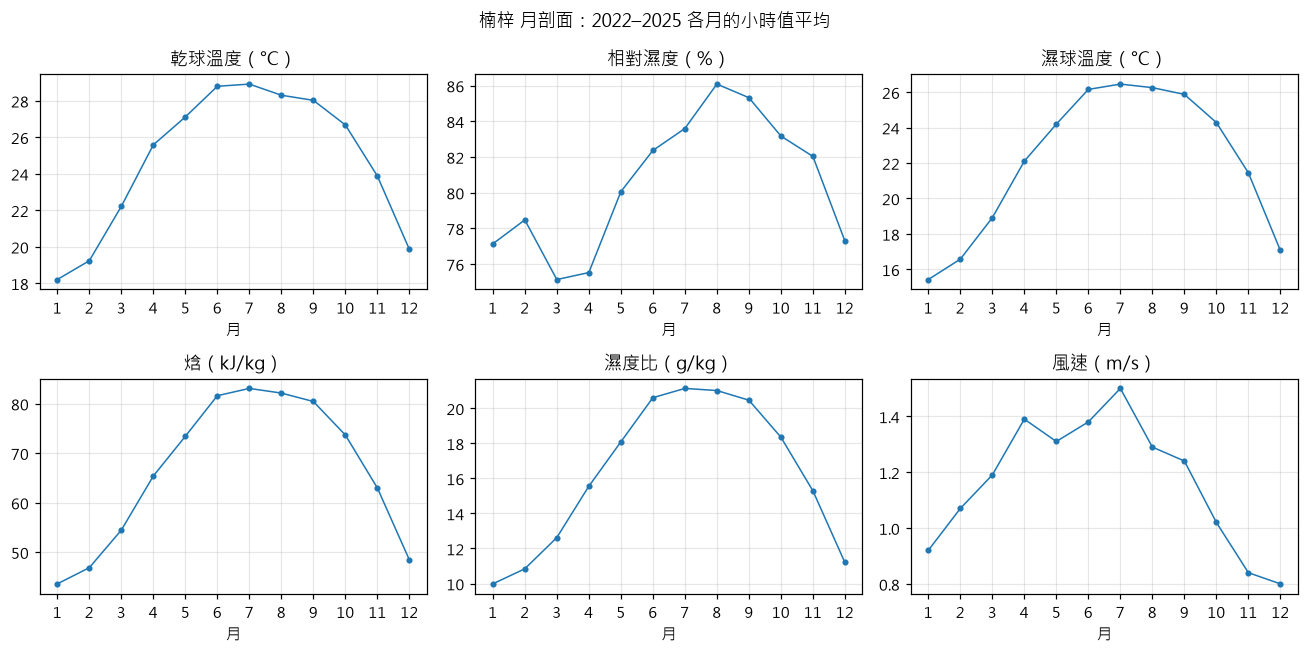

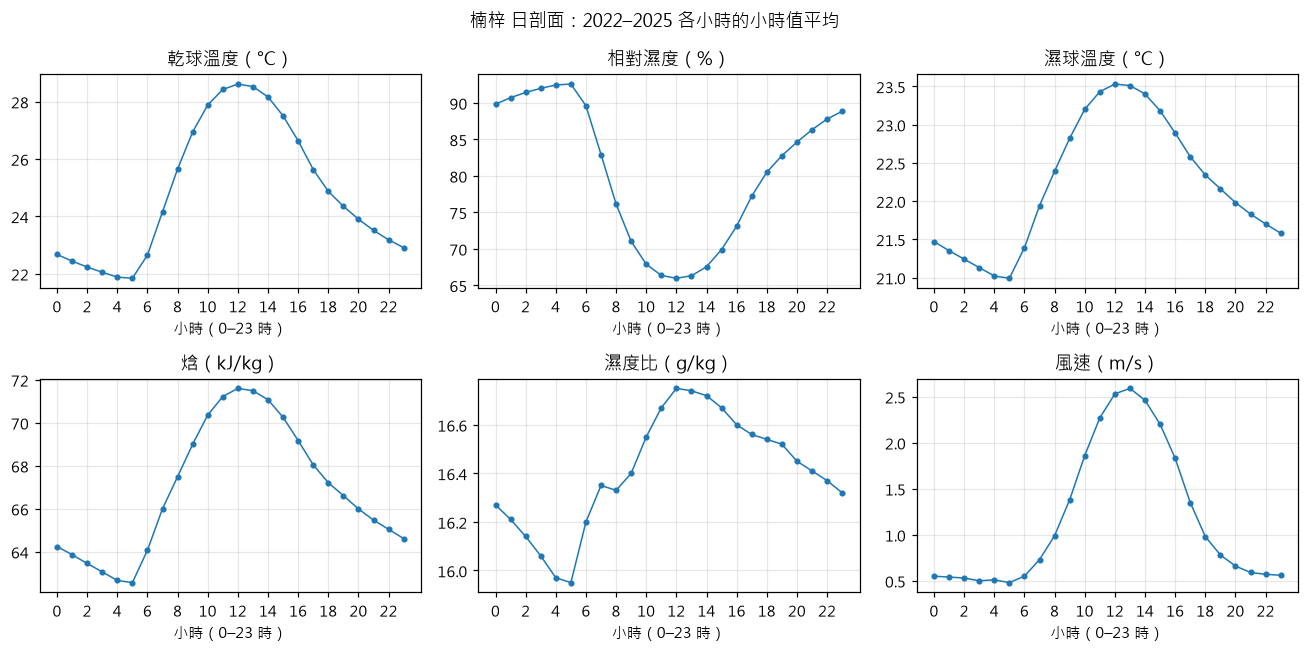

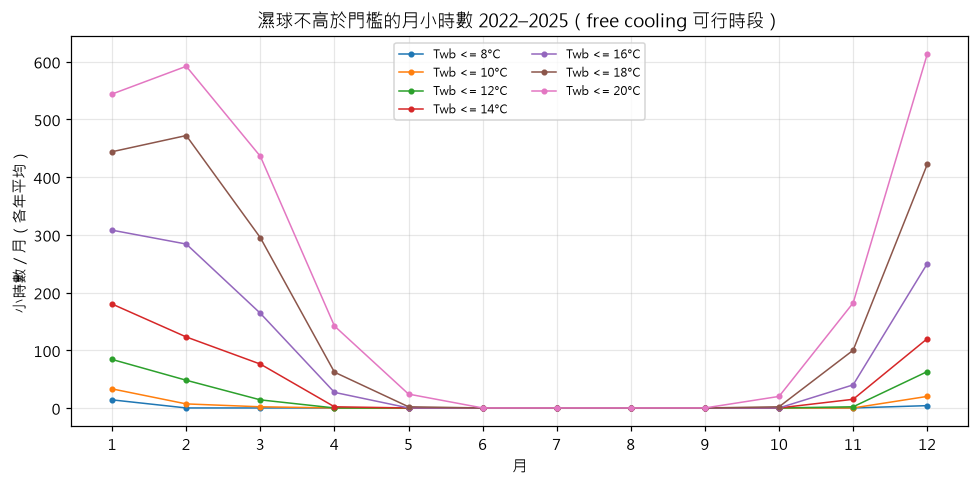

In [26]:
PROFILE_VARS = ["T", "RH", "Twb", "h", "W", "WS"]


def monthly_profile(df: pd.DataFrame, cols) -> pd.DataFrame:
    return df[cols].groupby(df.index.month).mean().T.round(2)


def diurnal_profile(df: pd.DataFrame, cols) -> pd.DataFrame:
    return df[cols].groupby(df.index.hour).mean().T.round(2)


def bin_hours(df: pd.DataFrame) -> pd.DataFrame:
    n_years = len(df.index.year.unique())
    d = df.dropna(subset=["T", "Twb"])
    db_bin = (np.floor(d["T"] / DB_BIN) * DB_BIN).astype(int)
    t1 = d.groupby(db_bin).agg(hours=("T", "size"), mcwb=("Twb", "mean"))
    t1 = t1.assign(hours_per_year=t1["hours"] / n_years, var="DB", bin_width=DB_BIN).round(1)
    wb_bin = (np.floor(d["Twb"] / WB_BIN) * WB_BIN).astype(int)
    t2 = d.groupby(wb_bin).agg(hours=("Twb", "size"))
    t2 = t2.assign(hours_per_year=t2["hours"] / n_years, mcwb=np.nan, var="WB", bin_width=WB_BIN).round(1)
    out = pd.concat([t1, t2]).rename_axis("bin_lower").reset_index()
    return out[["var", "bin_lower", "bin_width", "hours", "hours_per_year", "mcwb"]]


def threshold_hours(df: pd.DataFrame, col: str, thresholds) -> tuple:
    '''回傳 (逐年小時數表, 逐月平均小時數表)：col 不高於門檻的小時數。'''
    s = df[col].dropna()
    by_year = pd.DataFrame({thr: (s <= thr).groupby(s.index.year).sum() for thr in thresholds})
    by_year.loc["mean"] = by_year.mean()
    n_years = len(s.index.year.unique())
    by_month = pd.DataFrame({thr: (s <= thr).groupby(s.index.month).sum() / n_years for thr in thresholds})
    by_year.columns.name = f"{col} <= °C"; by_month.columns.name = f"{col} <= °C"
    return by_year.round(0), by_month.round(0)


mon = monthly_profile(main, PROFILE_VARS)
diu = diurnal_profile(main, PROFILE_VARS)
profiles = pd.concat([
    mon.stack().rename("value").reset_index().set_axis(["var", "bin", "value"], axis=1).assign(kind="month"),
    diu.stack().rename("value").reset_index().set_axis(["var", "bin", "value"], axis=1).assign(kind="hour"),
], ignore_index=True)[["kind", "var", "bin", "value"]]
profiles.to_csv(PROC_DIR / f"{PREFIX}_climate_profiles_{SITE_EN}.csv", index=False)
bins = bin_hours(main)
bins.to_csv(PROC_DIR / f"{PREFIX}_climate_bin_hours_{SITE_EN}.csv", index=False)
wb_year, wb_month = threshold_hours(main, "Twb", WB_THRESHOLDS)
db_year, db_month = threshold_hours(main, "T", DB_THRESHOLDS)
print("5.1 月剖面（各月小時值平均）"); display(mon)
print("5.2 乾球 bin 小時數（每年平均，附同時濕球）"); display(bins[bins["var"] == "DB"].set_index("bin_lower")[["hours_per_year", "mcwb"]].T)
print("5.3 濕球不高於門檻的年小時數（逐年與平均）"); display(wb_year)
print("5.4 乾球不高於門檻的年小時數"); display(db_year)


def _plot_profiles(table: pd.DataFrame, xlabel: str, title: str, fname: str, xtick_step: int = 1):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for ax, var in zip(axes.ravel(), table.index):
        ax.plot(table.columns, table.loc[var], marker="o", ms=3, lw=1)
        ax.set_title(f"{LABELS[var]}（{UNITS[var]}）"); ax.set_xlabel(xlabel); ax.grid(alpha=0.3)
        ax.set_xticks(table.columns[::xtick_step])
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / fname); plt.show()


_plot_profiles(mon, "月", f"楠梓 月剖面：{YEAR_START}–{YEAR_END} 各月的小時值平均", f"{PREFIX}_monthly_profile_{SITE_EN}.png")
_plot_profiles(diu, "小時（0–23 時）", f"楠梓 日剖面：{YEAR_START}–{YEAR_END} 各小時的小時值平均", f"{PREFIX}_diurnal_profile_{SITE_EN}.png", xtick_step=2)

fig, ax = plt.subplots(figsize=(9, 4.5))
for thr in WB_THRESHOLDS:
    ax.plot(wb_month.index, wb_month[thr], marker="o", ms=3, lw=1, label=f"Twb <= {thr}°C")
ax.set_xticks(range(1, 13)); ax.set_xlabel("月"); ax.set_ylabel("小時數／月（各年平均）"); ax.grid(alpha=0.3)
ax.set_title(f"濕球不高於門檻的月小時數 {YEAR_START}–{YEAR_END}（free cooling 可行時段）")
ax.legend(fontsize=8, ncol=2); fig.tight_layout()
fig.savefig(FIG_DIR / f"{PREFIX}_freecooling_hours_{SITE_EN}.png"); plt.show()

## 6. 設計輸入表

把第 4、5 節的結果疊成一張長格式表 `02_design_inputs_Nanzih.csv`，欄位固定為 `category、item、metric、value、unit、note`，與 01 的設計輸入表同一格式，設計組篩 `category` 就能取用：

- **DESIGN_COOLING**：`item` 是條件（DB、WB、h），`metric` 是百分位（p0.4、p1、p2）與同時值（mcwb_p0.4 …）。
- **DESIGN_HEATING**：DB 的 p99.6、p99 與同時濕球。
- **EXTREME**：逐年極端值的各年平均（mean_of_annual）與最極端值（most_extreme）。
- **FREECOOL_WB**、**FREECOOL_DB**：`item` 是門檻（如 `<=12`），`metric` 是 hours_per_year；逐年與逐月的拆分在 notebook 內顯示，不進這張表。
- **STATION**：測站名稱、座標、海拔、資料期間，讓表自帶出處。

表中每個數字都是外氣條件的統計，哪一個百分位、哪一個門檻要用，由設計組依系統配置決定，本表不做選擇。

In [27]:
rows = []
stn = STATION_META.loc[STATION]
period_note = f"{main.index.min():%Y-%m-%d} – {main.index.max():%Y-%m-%d}，{len(main.dropna(subset=['T'])):,} 有效小時"
rows += [("STATION", "station", "name", f"{stn['name']}（{STATION}）", "", stn["address"]),
         ("STATION", "station", "lat_lon", f"{stn['lat']}, {stn['lon']}", "WGS84", f"海拔 {stn['alt_m']} m"),
         ("STATION", "station", "period", period_note, "", "氣象署 CODiS 逐時觀測；2022 年自 1 月 24 日起")]
for _, r in design.iterrows():
    cat = "DESIGN_COOLING" if r["season"] == "cooling" else "DESIGN_HEATING"
    tag = f"p{r['pct']:g}"
    note = f"一年約 {int(r['hours_per_year'])} 小時{'超過' if r['season'] == 'cooling' else '低於'}此值；{int(r['n_years'])} 年合併 {int(r['n_hours_pooled']):,} 小時"
    rows.append((cat, r["condition"], tag, r["value"], r["unit"], note))
    rows.append((cat, r["condition"], f"{r['coincident'].lower()}_{tag}", r["coincident_value"], "°C",
                 f"設計值 ±{COINCIDENT_HALF_WIDTH if r['condition'] != 'h' else 1.0} 內 {int(r['n_coincident'])} 小時的平均"))
for idx, r in ext_summary.iterrows():
    rows.append(("EXTREME", idx, "mean_of_annual", r["mean_of_annual"], "kJ/kg" if idx.startswith("h") else "°C", f"{YEAR_START}–{YEAR_END} 各年極端值的平均"))
    rows.append(("EXTREME", idx, "most_extreme", r["most_extreme"], "kJ/kg" if idx.startswith("h") else "°C", f"{YEAR_START}–{YEAR_END} 最極端的一年"))
for thr in WB_THRESHOLDS:
    rows.append(("FREECOOL_WB", f"<={thr}", "hours_per_year", wb_year.loc["mean", thr], "h", "濕球不高於門檻的年小時數（各年平均）；門檻由設計組依冰水回水溫度與水塔趨近溫度決定"))
for thr in DB_THRESHOLDS:
    rows.append(("FREECOOL_DB", f"<={thr}", "hours_per_year", db_year.loc["mean", thr], "h", "乾球不高於門檻的年小時數（各年平均）"))
design_inputs = pd.DataFrame(rows, columns=["category", "item", "metric", "value", "unit", "note"])
design_inputs.to_csv(PROC_DIR / f"{PREFIX}_design_inputs_{SITE_EN}.csv", index=False)
print("6. 設計輸入表（長格式，唯一要交給設計組的檔）")
display(design_inputs)

6. 設計輸入表（長格式，唯一要交給設計組的檔）


,category,item,metric,value,unit,note
0,STATION,station,name,高雄（467441）,,高雄市楠梓區德民路28號
1,STATION,station,lat_lon,"22.730432, 120.312516",WGS84,海拔 11.8 m
2,STATION,station,period,"2022-01-24 – 2025-12-31，34,506 有效小時",,氣象署 CODiS 逐時觀測；2022 年自 1 月 24 日起
3,DESIGN_COOLING,DB,p0.4,33.8,°C,"一年約 35 小時超過此值；4 年合併 34,365 小時"
4,DESIGN_COOLING,DB,mcwb_p0.4,27.1,°C,設計值 ±0.5 內 269 小時的平均
5,DESIGN_COOLING,WB,p0.4,28.41,°C,"一年約 35 小時超過此值；4 年合併 34,365 小時"
6,DESIGN_COOLING,WB,mcdb_p0.4,31.88,°C,設計值 ±0.5 內 518 小時的平均
7,DESIGN_COOLING,h,p0.4,92.16,kJ/kg,"一年約 35 小時超過此值；4 年合併 34,365 小時"
8,DESIGN_COOLING,h,mcdb_p0.4,31.73,°C,設計值 ±1.0 內 192 小時的平均
9,DESIGN_COOLING,DB,p1,33.2,°C,"一年約 88 小時超過此值；4 年合併 34,365 小時"


## 7. 小結

要特別注意的事：

- **資料只有 2022 年 1 月 24 日起的四年**，比 ASHRAE 設計條件慣用的 25 年短，年際代表性較弱；報告引用時註明。若要拉長，`EXTRA_STATIONS` 加入舊高雄站 467440（前鎮，距楠梓約 18 km）可取得 1931 年起的資料，但站址不同。
- **濕球與焓是算出來的**，不是量測；計算用測站氣壓，若設計組慣用海平面氣壓或標準大氣壓，差異在 0.1 kJ/kg 等級。
- **設計值的百分位與 free cooling 門檻本表都只列出候選**，選擇留給設計組。
- 有效率低於門檻的變數／年份見第 4.3 節 `low_coverage` 欄；2022 年因 1 月 24 日才設站，有效率略低屬正常。


【楠梓（氣象署高雄站 467441）2022–2025 外氣氣候摘要】
- 夏季設計條件 0.4%：乾球 33.8°C（同時濕球 27.1°C）；濕球 28.41°C（同時乾球 31.88°C）；焓 92.16 kJ/kg。
- 冬季設計條件 99.6%：乾球 11.0°C。
- 逐年極端：最高乾球平均 35.2°C（最高 36.3°C）、最高濕球平均 29.2°C、最低乾球平均 8.7°C。
- 濕球不高於門檻的年小時數：≤8°C 18 h、≤10°C 61 h、≤12°C 210 h、≤14°C 516 h、≤16°C 1073 h、≤18°C 1800 h、≤20°C 2551 h。
- 年平均乾球 24.9°C、相對濕度 81%、濕球 22.2°C、焓 66.9 kJ/kg。
- 有效率低於 75% 的變數／年份：無。